In [ ]:
import pandas as pd 
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.feature_extraction import DictVectorizer
from sklearn.metrics import roc_auc_score
import numpy as np
from sklearn.model_selection import KFold

url_data = 'https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv'


In [30]:
df = pd.read_csv(url_data)
df.info(), len(df)

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   lead_source               4852 non-null   str    
 1   industry                  4760 non-null   str    
 2   employment_status         4806 non-null   str    
 3   location                  4792 non-null   str    
 4   annual_income             4631 non-null   float64
 5   number_of_courses_viewed  5000 non-null   int64  
 6   interaction_count         5000 non-null   int64  
 7   lead_score                4965 non-null   float64
 8   converted                 5000 non-null   int64  
dtypes: float64(2), int64(3), str(4)
memory usage: 351.7 KB


(None, 5000)

In [31]:
categorical_cols = df.select_dtypes(include=["str", "object", "category"]).columns.tolist()
numerical_cols = df.select_dtypes(include="number").columns.drop("converted").tolist()
target_col = 'converted'

In [32]:
print(df.isna().sum())

df[categorical_cols] = df[categorical_cols].fillna("NA")
df[numerical_cols] = df[numerical_cols].fillna(0.0)

print(df.isna().sum())

lead_source                 148
industry                    240
employment_status           194
location                    208
annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
converted                     0
dtype: int64
lead_source                 0
industry                    0
employment_status           0
location                    0
annual_income               0
number_of_courses_viewed    0
interaction_count           0
lead_score                  0
converted                   0
dtype: int64


In [33]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=1
)

In [34]:
df[numerical_cols[0]]

0       88160.0
1       72688.0
2       44697.0
3           0.0
4       24062.0
         ...   
4995    45834.0
4996    84831.0
4997    53636.0
4998    69430.0
4999    81355.0
Name: annual_income, Length: 5000, dtype: float64

In [35]:
from sklearn.metrics import roc_auc_score


auc_scores = {}

for col in numerical_cols:
    auc = roc_auc_score(df_train[target_col], df_train[col])

    if auc < 0.5:
        auc = roc_auc_score(df_train[target_col], -df_train[col])

    auc_scores[col] = auc

# Display AUC scores in descending order
print(pd.Series(auc_scores).sort_values(ascending=False))

lead_score                  0.788225
interaction_count           0.764920
number_of_courses_viewed    0.722989
annual_income               0.608198
dtype: float64


In [36]:


features = categorical_cols + numerical_cols

train_dicts = df_train[features].to_dict(orient="records")
val_dicts = df_val[features].to_dict(orient="records")

transform = DictVectorizer(sparse=False)

X_train = transform.fit_transform(train_dicts)
X_val = transform.transform(val_dicts)

model = LogisticRegression(solver="liblinear", C=1.0, max_iter=1000)
model.fit(X_train, df_train[target_col])

y_pred = model.predict_proba(X_val)[:, 1]

auc = roc_auc_score(df_val[target_col], y_pred)
print(f"Validation AUC: {auc:.4f}")

Validation AUC: 0.7318


In [41]:
def confusion_matrix(y_pred, y_true):
    cm = {}
    cm['tp'] = np.sum((y_pred == 1) & (y_true == 1))
    cm['tn'] = np.sum((y_pred == 0) & (y_true == 0))
    cm['fp'] = np.sum((y_pred == 1) & (y_true == 0))
    cm['fn'] = np.sum((y_pred == 0) & (y_true == 1))
    return cm

def precision(cm):
    denominator = cm['tp'] + cm['fp']
    return cm['tp'] / denominator if denominator else 0.0

def recall(cm):
    denominator = cm['tp'] + cm['fn']
    return cm['tp'] / denominator if denominator else 0.0


Best threshold: 0.63


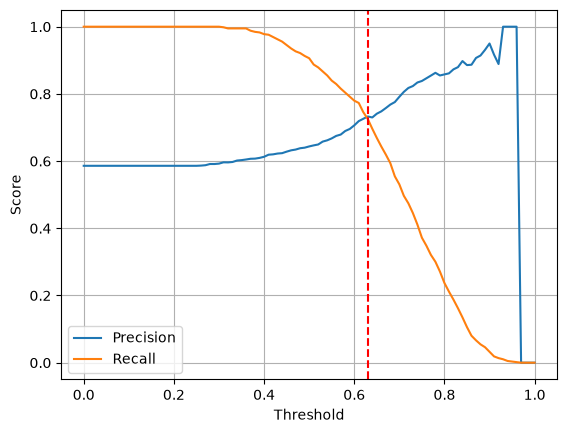

In [52]:
thresholds = np.arange(0, 1.01, 0.01)
y_true = df_val[target_col].values

results = {"threshold": [], "precision": [], "recall": []}

for t in thresholds:
    y_pred_th = (y_pred >= t).astype(int)
    cm = confusion_matrix(y_pred_th, y_true)

    results["threshold"].append(t)
    results["precision"].append(precision(cm))
    results["recall"].append(recall(cm))

# Convert dictionary to DataFrame
results = pd.DataFrame(results)

# Calculate difference
results["difference"] = abs(results["precision"] - results["recall"])

# Exclude cases where both metrics are zero
valid_results = results[
    (results["precision"] != 0) | (results["recall"] != 0)
]

# Find best threshold
best_th = valid_results.loc[
    valid_results["difference"].idxmin(), "threshold"
]

print(f"Best threshold: {best_th:.2f}")

# Plot
plt.plot(results["threshold"], results["precision"], label="Precision")
plt.plot(results["threshold"], results["recall"], label="Recall")
plt.axvline(best_th, color="red", linestyle="--")

plt.xlabel("Threshold")
plt.ylabel("Score")
plt.legend()
plt.grid()
plt.show()

In [57]:
results["f1"] = 2 * (results["precision"] * results["recall"]) / (results["precision"] + results["recall"])
results['threshold'][results['f1'].idxmax()]

np.float64(0.41000000000000003)

In [60]:
kfold = KFold(n_splits=5, shuffle=True, random_state=1)

scores = []

for train_idx, val_idx in kfold.split(df_full_train):

    df_train = df_full_train.iloc[train_idx]
    df_val = df_full_train.iloc[val_idx]

    y_train = df_train[target_col].values
    y_val = df_val[target_col].values

    train_dicts = df_train[features].to_dict(orient="records")
    val_dicts = df_val[features].to_dict(orient="records")

    transform = DictVectorizer(sparse=False)
    X_train = transform.fit_transform(train_dicts)
    X_val = transform.transform(val_dicts)

    model = LogisticRegression(solver="liblinear", C=1.0, max_iter=1000)
    model.fit(X_train, y_train)

    y_pred = model.predict_proba(X_val)[:, 1]
    auc = roc_auc_score(y_val, y_pred)

    scores.append(auc)


print(f"std auuc: {np.std(scores):.3f}")

std auuc: 0.007


In [62]:
kfold = KFold(n_splits=5, shuffle=True, random_state=1)

results = []

for C in [0.000001, 0.001, 1]:
    scores = []

    for train_idx, val_idx in kfold.split(df_full_train):
        train = df_full_train.iloc[train_idx]
        val = df_full_train.iloc[val_idx]

        dv = DictVectorizer(sparse=False)
        X_train = dv.fit_transform(train[features].to_dict(orient="records"))
        X_val = dv.transform(val[features].to_dict(orient="records"))

        model = LogisticRegression(solver="liblinear", C=C, max_iter=1000)
        model.fit(X_train, train[target_col])

        y_pred = model.predict_proba(X_val)[:, 1]
        scores.append(roc_auc_score(val[target_col], y_pred))

    results.append({
        "C": C,
        "mean": round(np.mean(scores), 3),
        "std": round(np.std(scores), 3)
    })

results = pd.DataFrame(results)
print(results)

# Best C
results.sort_values(
    ["mean", "std", "C"],
    ascending=[False, True, True]
).iloc[0]

          C   mean    std
0  0.000001  0.617  0.019
1  0.001000  0.749  0.010
2  1.000000  0.732  0.007


C       0.001
mean    0.749
std     0.010
Name: 1, dtype: float64